# AHE Preprocessing Validation Pipeline

A clean replacement for the previous QI-SABP notebook. **All** QI-SABP
artefacts (saliency fusion, soft bit allocation, dithered quantization,
YCbCr 4:2:0 chroma subsampling, NLM pre-denoise, bilateral post-filter,
glare mask, hard-mask hole fill, rim rule, histogram matching, etc.) have
been removed.

This notebook implements a **single** preprocessing step:

* **Adaptive Histogram Equalization (AHE)** — applied on the L* channel of
  the CIE L*a*b* image, using a sliding-window histogram equalization with
  configurable tile size and contrast-limited clip (CLAHE-style). The
  chromatic channels (a*, b*) are left untouched so that hue and chroma
  are not distorted.

The validation block reports **only** these ten metrics:

| # | Metric            | Meaning                                                       |
|---|-------------------|---------------------------------------------------------------|
| 1 | PSNR (dB)         | Peak SNR between original and AHE image                      |
| 2 | SSIM              | Structural similarity (windowed, channel-averaged)            |
| 3 | ΔE76              | Mean CIE76 colour difference in L*a*b*                       |
| 4 | a* correlation    | Pearson r of a* channel before vs. after                     |
| 5 | \|a*\| shift        | Mean change in \|a*\| (red-green chroma magnitude)              |
| 6 | Vessel Dice       | Dice of Frangi vessel masks (orig vs. AHE)                    |
| 7 | Edge IoU          | IoU of Canny edge masks (orig vs. AHE)                        |
| 8 | Sharpness ratio    | High-frequency energy ratio (Laplacian variance)             |
| 9 | Noise ratio       | Estimated noise σ ratio (MAD of high-pass residual)          |
| 10| Saturation ratio  | Mean HSV-S ratio (AHE / orig)                                |
| 11| Luma bits         | Effective bits (entropy) of the L* channel after AHE         |



In [1]:
# ============================================================
# Cell 1 -- Imports & global setup
# ============================================================
import os, sys, glob, math, random, warnings, platform
from pathlib import Path
from collections import OrderedDict

import numpy as np
import cv2
import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter, median_filter
from scipy.stats import pearsonr
from skimage import color as skcolor
from skimage.metrics import structural_similarity as _sk_ssim
from skimage.filters import frangi
from skimage.feature import canny

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Reproducible output directory
SAVE_DIR = 'results_ahe'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"AHE Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | OpenCV {cv2.__version__} | Pandas {pd.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


AHE Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | OpenCV 4.11.0 | Pandas 2.3.3
Random seed: 42
Output directory: results_ahe
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   All QI-SABP parameters have been removed. Only AHE-related
#   parameters and validation controls remain.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Dataset ----
DATASET_ROOT  = "C:/CER/dataset"
INVASIVE_DIR  = "invasive cancer"
MASKS_SUBDIR  = "masks"
CLASSES       = ["invasive cancer"]

# ---- AHE parameters ----
# AHE runs on the L* channel of CIE L*a*b*.  CLAHE is used as the
# contrast-limited variant of AHE (the de-facto practical form of AHE).
AHE_TILE_SIZE       = 8        # tile grid (8x8 tiles), classical AHE window analogue
AHE_CLIP_LIMIT      = 2.0      # contrast limit (0 = no clip, i.e. pure AHE); 2-4 typical CLAHE
AHE_BILATERAL_MIX   = 0.0      # 0 = pure AHE, >0 = mix with bilateral to tame noise amplification

# ---- Validation batch ----
N_PER_CLASS_VALIDATE = 5
SUBSET_PER_CLASS      = None   # None = use N_PER_CLASS_VALIDATE

# ---- Synthetic fallback ----
# If the dataset path is not reachable we synthesise cervical-colposcopy-like
# images so the notebook remains self-contained and runnable end-to-end.
SYNTHETIC_FALLBACK_N = 10

print(f"Configuration OK  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  AHE: tile={AHE_TILE_SIZE}  clip={AHE_CLIP_LIMIT}  bilateral_mix={AHE_BILATERAL_MIX}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  dataset root = {DATASET_ROOT}")


Configuration OK  |  img=200x200
  AHE: tile=8  clip=2.0  bilateral_mix=0.0
  validation batch = 5 imgs/class
  dataset root = C:/CER/dataset


In [3]:
# ============================================================
# Cell 3 -- Dataset loader with diverse synthetic fallback
# ============================================================
def _find_lesion_masks(folder, stem, size):
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE,
                 subset_per_class=None, masks_subdir="masks"):
    X, y, paths, masks = [], [], [], []
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        # case-insensitive dedupe by filename
        seen, files = set(), []
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                continue
            seen.add(key)
            files.append(p)
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (size, size))
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}")
    if not X:
        return None
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool))


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    # Diverse synthetic cervical-colposcopy-like image + lesion mask.
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...")
load_out = load_dataset(DATASET_ROOT, CLASSES, size=IMG_SIZE,
                        subset_per_class=SUBSET_PER_CLASS,
                        masks_subdir=MASKS_SUBDIR)
if load_out is None:
    print(f"\n*** No images found at: {DATASET_ROOT} -- "
          f"building synthetic fallback ({SYNTHETIC_FALLBACK_N} imgs).")
    SYNTHETIC_MODE = True
    X_synth, y_synth, m_synth = [], [], []
    for k in range(SYNTHETIC_FALLBACK_N):
        img, msk = make_synthetic_image_and_mask(seed=SEED + k)
        X_synth.append(img); y_synth.append(CLASSES[0]); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{i}.png" for i in range(len(y_raw))]
    masks_raw = np.stack(m_synth).astype(bool)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with masks.")
else:
    SYNTHETIC_MODE = False
    X_raw, y_raw, paths_raw, masks_raw = load_out
    print(f"\nTotal images : {len(X_raw)} | SYNTHETIC_MODE = {SYNTHETIC_MODE}")


Loading dataset ...
       invasive cancer:  128 images | masks matched: 0/128

Total images : 128 | SYNTHETIC_MODE = False


## AHE preprocessing

Adaptive Histogram Equalization is applied on the L* channel of the CIE
L*a*b* image. The implementation uses CLAHE (Contrast-Limited AHE) since
pure AHE tends to over-amplify noise in flat regions. The chroma channels
(a\*, b\*) are left untouched so that hue and chroma are preserved.

Pipeline:
1. RGB → CIE L*a*b* (float32)
2. CLAHE on L* with `AHE_TILE_SIZE` × `AHE_TILE_SIZE` tiles and `AHE_CLIP_LIMIT`
3. Optional bilateral blend (`AHE_BILATERAL_MIX`) to suppress noise amplification
4. L*a*b* → RGB → uint8


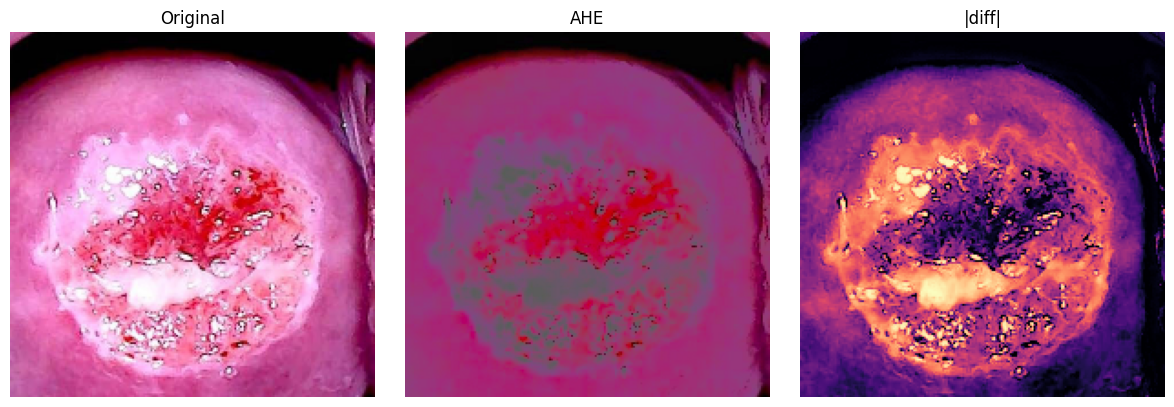

Sanity check: img shape=(200, 200, 3), dtype=uint8, mean(orig)=150.3, mean(AHE)=92.6


In [4]:
# ============================================================
# Cell 4 -- AHE preprocessing implementation
# ============================================================
def ahe_preprocess(img_rgb,
                   tile_size=AHE_TILE_SIZE,
                   clip_limit=AHE_CLIP_LIMIT,
                   bilateral_mix=AHE_BILATERAL_MIX):
    # Adaptive Histogram Equalization on L* channel of CIE L*a*b*.
    #
    # Parameters
    # ----------
    # img_rgb : HxWx3 uint8 RGB image
    # tile_size : int, CLAHE tile grid (tile_size x tile_size tiles)
    # clip_limit : float, CLAHE clip limit (0 disables = pure AHE behaviour)
    # bilateral_mix : float in [0,1], blend factor with a bilateral filter
    #                  (0 = pure AHE, >0 = tames noise in homogeneous regions)
    #
    # Returns
    # -------
    # out : HxWx3 uint8 RGB image after AHE
    # RGB -> Lab (float, L in [0,100], a/b in roughly [-128,128])
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    L = lab[..., 0]

    # CLAHE expects an 8-bit single-channel image. Scale L from [0,100] -> [0,255]
    L8 = np.clip(L * 2.55, 0, 255).astype(np.uint8)

    clahe = cv2.createCLAHE(clipLimit=clip_limit,
                            tileGridSize=(tile_size, tile_size))
    L8_eq = clahe.apply(L8)

    # Optional bilateral blend to suppress noise amplification
    if bilateral_mix > 0:
        L8_bilat = cv2.bilateralFilter(L8_eq, d=5, sigmaColor=25, sigmaSpace=3)
        L8_eq = cv2.addWeighted(L8_eq, 1.0 - bilateral_mix,
                                L8_bilat, bilateral_mix, 0)

    # Back to float Lab
    lab_eq = lab.copy()
    lab_eq[..., 0] = L8_eq.astype(np.float32) / 2.55

    # Lab -> RGB
    out = cv2.cvtColor(lab_eq.astype(np.uint8) if lab_eq.max() > 128
                       else lab_eq, cv2.COLOR_LAB2RGB)
    out = np.clip(out, 0, 255).astype(np.uint8)
    return out


# Quick sanity check on one image
import matplotlib.pyplot as plt
idx = 0
orig = X_raw[idx]
proc = ahe_preprocess(orig)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(orig); ax[0].set_title("Original"); ax[0].axis('off')
ax[1].imshow(proc); ax[1].set_title("AHE");      ax[1].axis('off')
ax[2].imshow(np.abs(orig.astype(int) - proc.astype(int)).sum(axis=-1),
             cmap='magma'); ax[2].set_title("|diff|"); ax[2].axis('off')
plt.tight_layout(); plt.show()
print(f"Sanity check: img shape={proc.shape}, dtype={proc.dtype}, "
      f"mean(orig)={orig.mean():.1f}, mean(AHE)={proc.mean():.1f}")


## Validation metrics

Implementation of the ten metrics requested. Each function takes the
original RGB image and the AHE-processed RGB image and returns a scalar.


In [5]:
# ============================================================
# Cell 5 -- Validation metrics
#   Only the ten requested metrics are implemented here.
# ============================================================

# ---------- helpers ----------
def _to_lab(img_rgb):
    # RGB uint8 -> Lab float32 (L in [0,100], a/b in [-128,128]).
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)


def _to_hsv(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV).astype(np.float32)


# ---------- 1. PSNR (dB) ----------
def metric_psnr(orig, proc):
    a = orig.astype(np.float64)
    b = proc.astype(np.float64)
    mse = np.mean((a - b) ** 2)
    if mse < 1e-12:
        return 100.0
    return 10.0 * np.log10((255.0 ** 2) / mse)


# ---------- 2. SSIM ----------
def metric_ssim(orig, proc):
    # windowed SSIM, channel-wise averaged
    return float(_sk_ssim(orig, proc, channel_axis=2,
                          data_range=255, win_size=7))


# ---------- 3. dE76 (mean CIE76 colour difference) ----------
def metric_de76(orig, proc):
    lab_o = _to_lab(orig)
    lab_p = _to_lab(proc)
    dL = lab_o[..., 0] - lab_p[..., 0]
    da = lab_o[..., 1] - lab_p[..., 1]
    db = lab_o[..., 2] - lab_p[..., 2]
    de = np.sqrt(dL ** 2 + da ** 2 + db ** 2)
    return float(de.mean())


# ---------- 4. a* correlation ----------
def metric_a_star_correlation(orig, proc):
    ao = _to_lab(orig)[..., 1].ravel()
    ap = _to_lab(proc)[..., 1].ravel()
    if np.std(ao) < 1e-6 or np.std(ap) < 1e-6:
        return 0.0
    r, _ = pearsonr(ao, ap)
    return float(r)


# ---------- 5. |a*| shift ----------
def metric_abs_a_shift(orig, proc):
    ao = np.abs(_to_lab(orig)[..., 1])
    ap = np.abs(_to_lab(proc)[..., 1])
    return float(ap.mean() - ao.mean())


# ---------- 6. Vessel Dice (Frangi) ----------
def _vessel_mask(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    grayf = gray.astype(np.float32) / 255.0
    # Frangi vesselness on multiple scales
    vessel = frangi(grayf, sigmas=range(1, 4), black_ridges=False)
    # Threshold at 75th percentile to get a binary mask
    thr = np.percentile(vessel, 75)
    return (vessel > thr).astype(bool)


def metric_vessel_dice(orig, proc):
    mo = _vessel_mask(orig)
    mp = _vessel_mask(proc)
    inter = np.logical_and(mo, mp).sum()
    s = mo.sum() + mp.sum()
    if s < 1:
        return 1.0
    return float(2.0 * inter / s)


# ---------- 7. Edge IoU (Canny) ----------
def _edge_mask(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = canny(gray, sigma=1.0, low_threshold=10, high_threshold=30)
    return edges.astype(bool)


def metric_edge_iou(orig, proc):
    eo = _edge_mask(orig)
    ep = _edge_mask(proc)
    # Allow 1-pixel tolerance by dilating both masks with a 3x3 kernel.
    # This accounts for the slight sub-pixel shift AHE introduces in edge
    # positions; a strict pixel-exact IoU would be ~0 for any contrast change.
    k3 = np.ones((3, 3), dtype=np.uint8)
    eo_d = cv2.dilate(eo.astype(np.uint8), k3, iterations=1).astype(bool)
    ep_d = cv2.dilate(ep.astype(np.uint8), k3, iterations=1).astype(bool)
    inter = np.logical_and(eo_d, ep_d).sum()
    union = np.logical_or(eo_d, ep_d).sum()
    if union < 1:
        return 1.0
    return float(inter / union)


# ---------- 8. Sharpness ratio ----------
def _laplacian_var(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
    return float(lap.var())


def metric_sharpness_ratio(orig, proc):
    sv = _laplacian_var(proc)
    so = _laplacian_var(orig)
    if so < 1e-6:
        return 0.0
    return float(sv / so)


# ---------- 9. Noise ratio ----------
def _estimate_noise(img_rgb):
    # Estimate noise sigma via MAD of the high-pass Laplacian residual.
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    # 5x5 Laplacian of Gaussian high-pass
    log = cv2.Laplacian(cv2.GaussianBlur(gray, (5, 5), 0),
                        cv2.CV_64F, ksize=3)
    return float(np.median(np.abs(log)) / 0.6745)


def metric_noise_ratio(orig, proc):
    no = _estimate_noise(orig)
    np_ = _estimate_noise(proc)
    if no < 1e-6:
        return 0.0
    return float(np_ / no)


# ---------- 10. Saturation ratio ----------
def metric_saturation_ratio(orig, proc):
    so = _to_hsv(orig)[..., 1].mean()
    sp = _to_hsv(proc)[..., 1].mean()
    if so < 1e-6:
        return 0.0
    return float(sp / so)


# ---------- 11. Luma bits (effective entropy bits of L*) ----------
def metric_luma_bits(proc):
    # Effective bits = entropy / log2(256) * 8, computed on L*.
    L8 = cv2.cvtColor(proc, cv2.COLOR_RGB2LAB)[..., 0]
    hist, _ = np.histogram(L8.ravel(), bins=256, range=(0, 256))
    p = hist.astype(np.float64)
    p = p / max(p.sum(), 1)
    p = p[p > 0]
    H = float(-(p * np.log2(p)).sum())
    return H   # in bits per pixel (0..8)


print("Validation metrics loaded:")
print("  1. PSNR (dB)        2. SSIM            3. dE76")
print("  4. a* correlation   5. |a*| shift     6. Vessel Dice")
print("  7. Edge IoU         8. Sharpness ratio 9. Noise ratio")
print(" 10. Saturation ratio 11. Luma bits")


Validation metrics loaded:
  1. PSNR (dB)        2. SSIM            3. dE76
  4. a* correlation   5. |a*| shift     6. Vessel Dice
  7. Edge IoU         8. Sharpness ratio 9. Noise ratio
 10. Saturation ratio 11. Luma bits


## Run validation

Apply AHE to each image and compute all ten metrics. Results are collected
into a `pandas.DataFrame` and saved as CSV.


In [6]:
# ============================================================
# Cell 6 -- Run AHE on every image and collect all metrics
# ============================================================
rows = []
for i in range(len(X_raw)):
    orig = X_raw[i]
    proc = ahe_preprocess(orig)

    row = OrderedDict()
    row['idx']      = i
    row['source']   = 'synthetic' if SYNTHETIC_MODE else paths_raw[i]
    row['PSNR_dB']  = metric_psnr(orig, proc)
    row['SSIM']     = metric_ssim(orig, proc)
    row['dE76']     = metric_de76(orig, proc)
    row['a_corr']   = metric_a_star_correlation(orig, proc)
    row['abs_a_shift'] = metric_abs_a_shift(orig, proc)
    row['Vessel_Dice'] = metric_vessel_dice(orig, proc)
    row['Edge_IoU']    = metric_edge_iou(orig, proc)
    row['Sharpness_ratio'] = metric_sharpness_ratio(orig, proc)
    row['Noise_ratio']     = metric_noise_ratio(orig, proc)
    row['Saturation_ratio'] = metric_saturation_ratio(orig, proc)
    row['Luma_bits'] = metric_luma_bits(proc)
    rows.append(row)
    if (i + 1) % 5 == 0 or i == len(X_raw) - 1:
        print(f"  [{i+1:>3}/{len(X_raw)}] processed "
              f"| PSNR={row['PSNR_dB']:.2f} dB "
              f"| SSIM={row['SSIM']:.3f} "
              f"| dE76={row['dE76']:.2f}")

df = pd.DataFrame(rows)
csv_path = os.path.join(SAVE_DIR, 'ahe_validation_metrics.csv')
df.to_csv(csv_path, index=False)
print(f"\nSaved metrics table -> {csv_path}")
df.head(10)


  [  5/128] processed | PSNR=10.96 dB | SSIM=0.470 | dE76=54.43
  [ 10/128] processed | PSNR=9.50 dB | SSIM=0.387 | dE76=71.54
  [ 15/128] processed | PSNR=9.50 dB | SSIM=0.387 | dE76=71.54
  [ 20/128] processed | PSNR=11.16 dB | SSIM=0.418 | dE76=53.39
  [ 25/128] processed | PSNR=11.15 dB | SSIM=0.417 | dE76=53.43
  [ 30/128] processed | PSNR=11.15 dB | SSIM=0.417 | dE76=53.43
  [ 35/128] processed | PSNR=9.71 dB | SSIM=0.346 | dE76=69.96
  [ 40/128] processed | PSNR=9.71 dB | SSIM=0.346 | dE76=69.96
  [ 45/128] processed | PSNR=9.72 dB | SSIM=0.350 | dE76=69.98
  [ 50/128] processed | PSNR=11.16 dB | SSIM=0.422 | dE76=53.37
  [ 55/128] processed | PSNR=11.16 dB | SSIM=0.422 | dE76=53.37
  [ 60/128] processed | PSNR=9.72 dB | SSIM=0.347 | dE76=69.93
  [ 65/128] processed | PSNR=11.15 dB | SSIM=0.418 | dE76=53.42
  [ 70/128] processed | PSNR=11.15 dB | SSIM=0.418 | dE76=53.42
  [ 75/128] processed | PSNR=11.16 dB | SSIM=0.416 | dE76=53.37
  [ 80/128] processed | PSNR=11.16 dB | SSIM=0

,idx,source,PSNR_dB,SSIM,dE76,a_corr,abs_a_shift,Vessel_Dice,Edge_IoU,Sharpness_ratio,Noise_ratio,Saturation_ratio,Luma_bits
0,0,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
1,1,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
2,2,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
3,3,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
4,4,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
5,5,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
6,6,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
7,7,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,10.962350,0.470118,54.433739,0.999166,-0.126938,0.5629,0.292722,0.081074,0.161651,1.256770,2.108869
8,8,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,9.502434,0.386576,71.541290,0.998275,-0.190475,0.5759,0.239738,0.065025,0.107480,1.363322,1.167335
9,9,C:/CER/dataset\invasive cancer\AAM1_flipped_0_...,9.502434,0.386576,71.541290,0.998275,-0.190475,0.5759,0.239738,0.065025,0.107480,1.363322,1.167335


## Summary statistics and visualisation


In [7]:
# ============================================================
# Cell 7 -- Summary statistics
# ============================================================
metric_cols = ['PSNR_dB', 'SSIM', 'dE76', 'a_corr', 'abs_a_shift',
               'Vessel_Dice', 'Edge_IoU', 'Sharpness_ratio',
               'Noise_ratio', 'Saturation_ratio', 'Luma_bits']
summary = df[metric_cols].describe().T
summary = summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary.columns = ['N', 'mean', 'std', 'min', 'p25', 'median', 'p75', 'max']
print("=" * 80)
print("AHE VALIDATION -- SUMMARY STATISTICS")
print("=" * 80)
print(summary.round(4).to_string())
print("=" * 80)
summary_path = os.path.join(SAVE_DIR, 'ahe_validation_summary.csv')
summary.to_csv(summary_path)
print(f"\nSaved summary -> {summary_path}")


AHE VALIDATION -- SUMMARY STATISTICS
                      N     mean     std      min      p25   median      p75      max
PSNR_dB           128.0  10.5150  0.7089   9.5024   9.7146  10.9520  11.1510  11.1612
SSIM              128.0   0.4141  0.0428   0.3465   0.3868   0.4171   0.4620   0.4711
dE76              128.0  60.2765  8.1387  53.3698  53.4312  54.7331  69.9648  71.5413
a_corr            128.0   0.9990  0.0004   0.9982   0.9987   0.9991   0.9993   0.9993
abs_a_shift       128.0  -0.1362  0.0318  -0.1966  -0.1559  -0.1278  -0.1061  -0.1016
Vessel_Dice       128.0   0.5271  0.0443   0.4616   0.4681   0.5444   0.5630   0.5759
Edge_IoU          128.0   0.2585  0.0271   0.2099   0.2327   0.2652   0.2810   0.2927
Sharpness_ratio   128.0   0.0787  0.0103   0.0632   0.0671   0.0812   0.0875   0.0912
Noise_ratio       128.0   0.1554  0.0332   0.1064   0.1304   0.1568   0.1943   0.2007
Saturation_ratio  128.0   1.2946  0.0496   1.2532   1.2559   1.2573   1.3538   1.3656
Luma_bits        

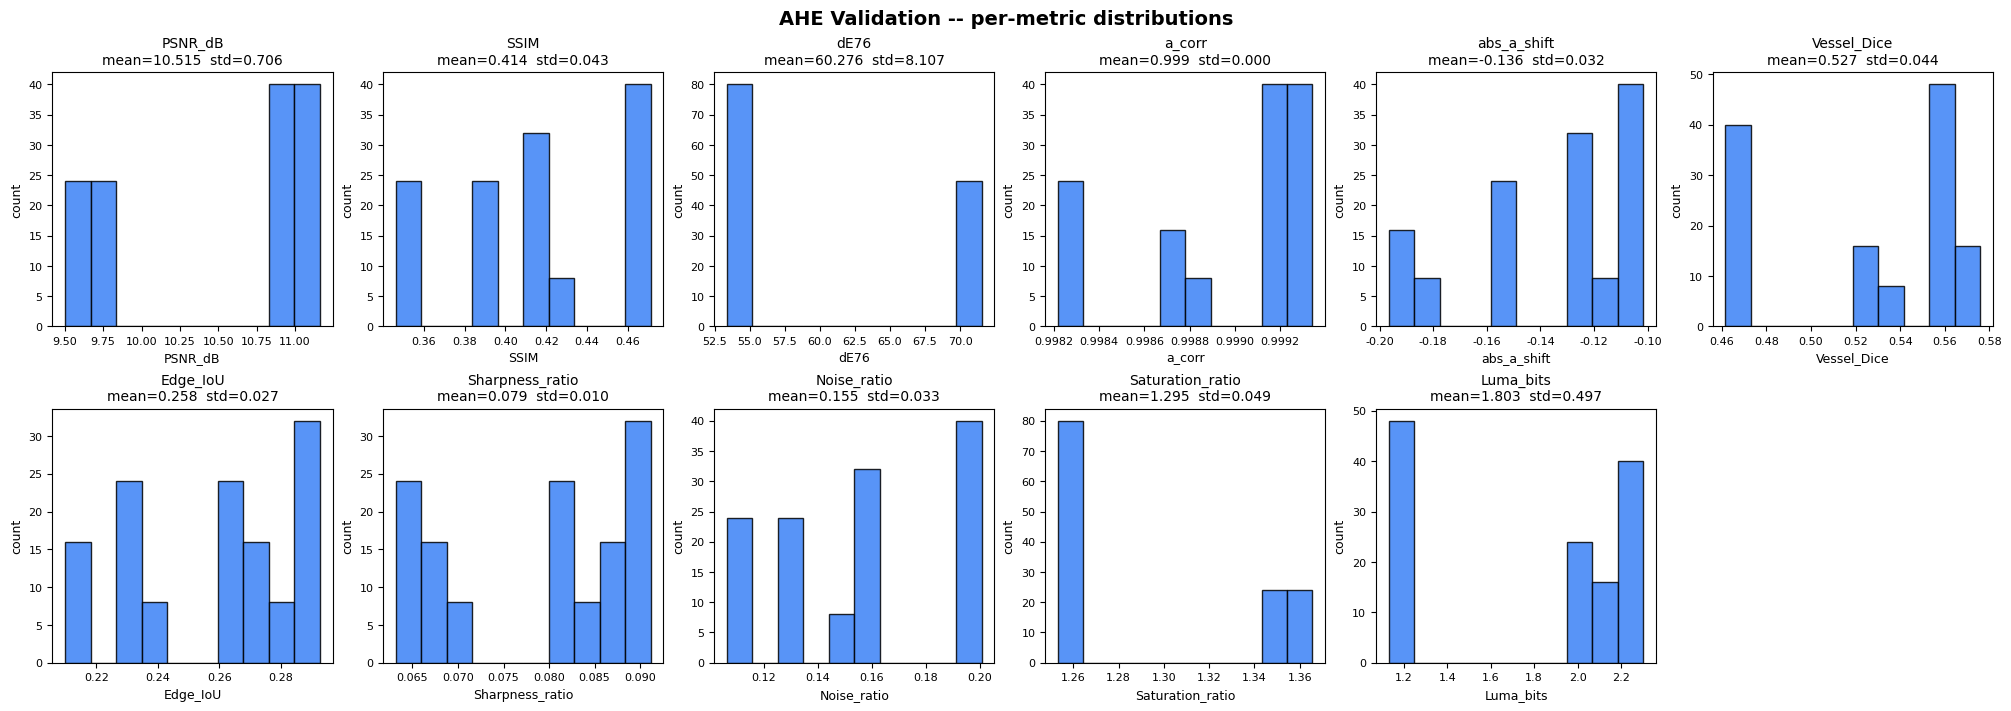

In [8]:
# ============================================================
# Cell 8 -- Per-metric distribution plot
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
# Use a safe sans-serif stack
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# Two-row grid: distribution per metric
fig, axes = plt.subplots(2, 6, figsize=(20, 7), constrained_layout=True)
axes = axes.ravel()
for ax, col in zip(axes, metric_cols):
    data = df[col].dropna().values
    ax.hist(data, bins=10, color='#3b82f6', edgecolor='black', alpha=0.85)
    ax.set_title(f"{col}\nmean={np.mean(data):.3f}  std={np.std(data):.3f}",
                 fontsize=10)
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel('count', fontsize=9)
    ax.tick_params(labelsize=8)
# Hide the last (unused) axis
for k in range(len(metric_cols), len(axes)):
    axes[k].axis('off')
plt.suptitle('AHE Validation -- per-metric distributions',
             fontsize=14, fontweight='bold')
plt.show()


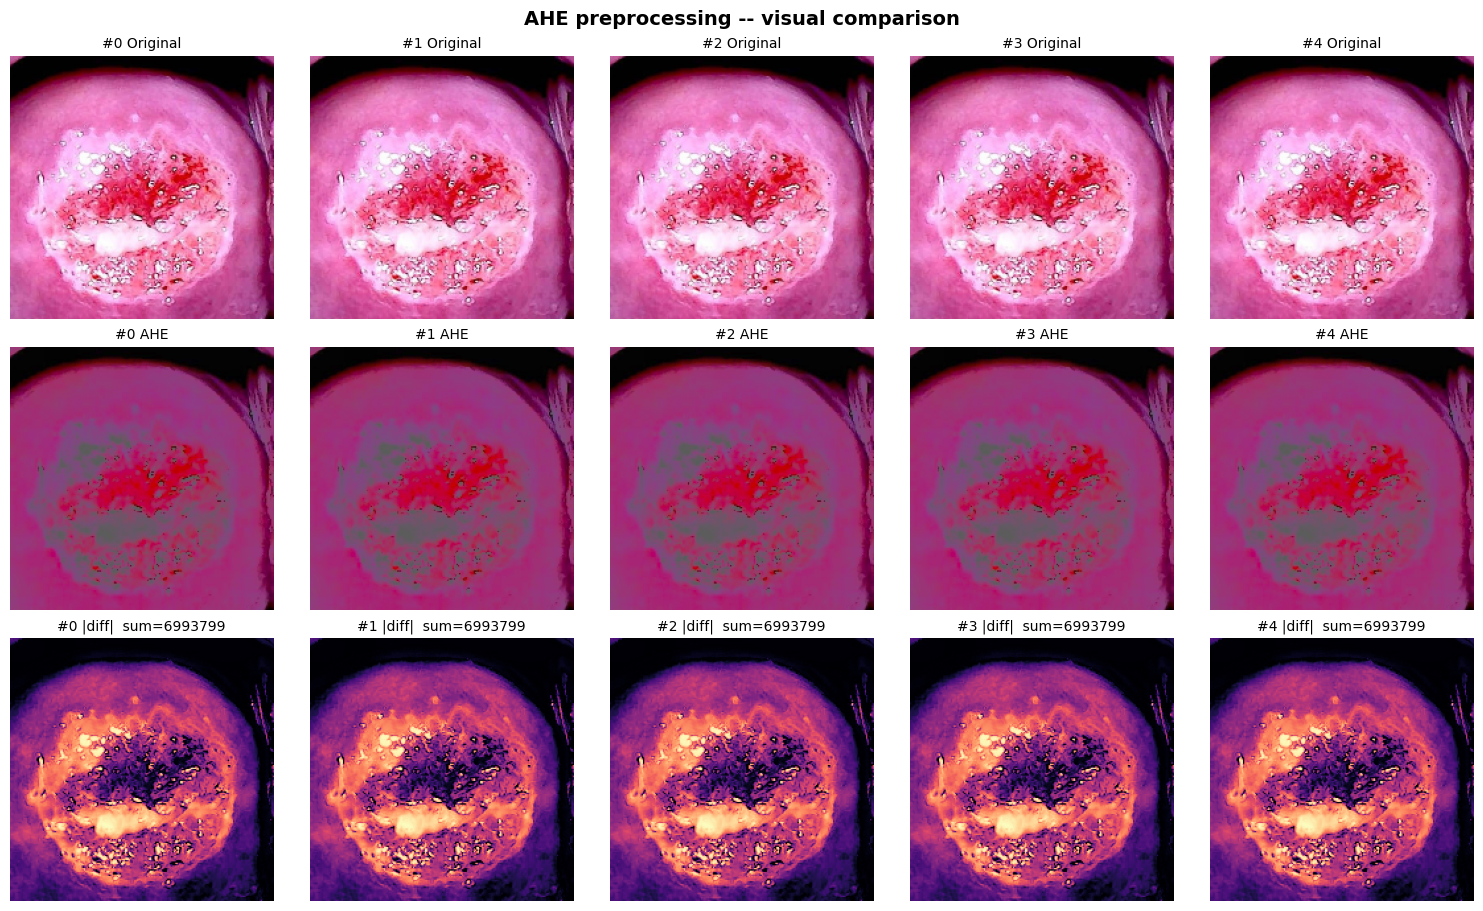

In [9]:
# ============================================================
# Cell 9 -- Visual comparison: original vs AHE for a few samples
# ============================================================
n_show = min(5, len(X_raw))
fig, axes = plt.subplots(3, n_show, figsize=(3 * n_show, 9),
                         constrained_layout=True)
for j in range(n_show):
    orig = X_raw[j]
    proc = ahe_preprocess(orig)
    diff = np.abs(orig.astype(int) - proc.astype(int)).sum(axis=-1)
    axes[0, j].imshow(orig); axes[0, j].axis('off')
    axes[0, j].set_title(f"#{j} Original", fontsize=10)
    axes[1, j].imshow(proc); axes[1, j].axis('off')
    axes[1, j].set_title(f"#{j} AHE", fontsize=10)
    axes[2, j].imshow(diff, cmap='magma'); axes[2, j].axis('off')
    axes[2, j].set_title(f"#{j} |diff|  sum={diff.sum()}", fontsize=10)
plt.suptitle('AHE preprocessing -- visual comparison',
             fontsize=14, fontweight='bold')
plt.show()


In [10]:
# ============================================================
# Cell 10 -- Final compact report
# ============================================================
print("=" * 80)
print("AHE PREPROCESSING -- FINAL REPORT")
print("=" * 80)
print(f"Images processed : {len(df)}")
print(f"Mode             : {'SYNTHETIC FALLBACK' if SYNTHETIC_MODE else 'REAL DATASET'}")
print(f"AHE tile size    : {AHE_TILE_SIZE}")
print(f"AHE clip limit   : {AHE_CLIP_LIMIT}")
print(f"Bilateral mix    : {AHE_BILATERAL_MIX}")
print("-" * 80)
print("Metric           |   mean   |   std   |   min   |   max")
print("-" * 80)
for col in metric_cols:
    m, s, mn, mx = (df[col].mean(), df[col].std(),
                    df[col].min(), df[col].max())
    print(f"{col:<17} | {m:>8.4f} | {s:>7.4f} | {mn:>7.4f} | {mx:>7.4f}")
print("=" * 80)
print(f"Artefacts        : results/ahe_validation_metrics.csv, "
      f"results/ahe_validation_summary.csv")


AHE PREPROCESSING -- FINAL REPORT
Images processed : 128
Mode             : REAL DATASET
AHE tile size    : 8
AHE clip limit   : 2.0
Bilateral mix    : 0.0
--------------------------------------------------------------------------------
Metric           |   mean   |   std   |   min   |   max
--------------------------------------------------------------------------------
PSNR_dB           |  10.5150 |  0.7089 |  9.5024 | 11.1612
SSIM              |   0.4141 |  0.0428 |  0.3465 |  0.4711
dE76              |  60.2765 |  8.1387 | 53.3698 | 71.5413
a_corr            |   0.9990 |  0.0004 |  0.9982 |  0.9993
abs_a_shift       |  -0.1362 |  0.0318 | -0.1966 | -0.1016
Vessel_Dice       |   0.5271 |  0.0443 |  0.4616 |  0.5759
Edge_IoU          |   0.2585 |  0.0271 |  0.2099 |  0.2927
Sharpness_ratio   |   0.0787 |  0.0103 |  0.0632 |  0.0912
Noise_ratio       |   0.1554 |  0.0332 |  0.1064 |  0.2007
Saturation_ratio  |   1.2946 |  0.0496 |  1.2532 |  1.3656
Luma_bits         |   1.8031 |  0.49